# Lista de Exercícios — Sistemas Lineares
## Método iterativo de Gauss–Seidel

**Disciplina:** Cálculo Numérico — Profa. Raquel J. Lobosco (UNIFESP)
**Aluno:** Matheus Bueno Christovão — RA 185302

Sistema estudado:

$$\begin{cases} 10x - y + 2z = 6 \\ -x + 11y - z = 22 \\ 2x - y + 10z = -10 \end{cases}$$

| Questões | Conteúdo |
|---|---|
| 1 a 3 | Forma matricial, dominância diagonal e fórmulas iterativas (resolução manuscrita, transcrita abaixo) |
| 4 | Três primeiras iterações à mão |
| 5 | Implementação em Python |
| 6 | Tabela das iterações |
| 7 | Gráficos de convergência |

> A resolução original, com as folhas manuscritas digitalizadas, está em `lista_gauss-seidel_resolucao.pdf`, nesta mesma pasta.

## Questão 1 — Forma matricial

$$\underbrace{\begin{bmatrix} 10 & -1 & 2 \\ -1 & 11 & -1 \\ 2 & -1 & 10 \end{bmatrix}}_{A}
\underbrace{\begin{bmatrix} x \\ y \\ z \end{bmatrix}}_{\mathbf{x}} =
\underbrace{\begin{bmatrix} 6 \\ 22 \\ -10 \end{bmatrix}}_{\mathbf{b}}$$

## Questão 2 — Dominância diagonal

A matriz é **estritamente diagonalmente dominante por linhas**, uma vez que

$$|a_{ii}| > \sum_{j \neq i} |a_{ij}|, \qquad i = 1, 2, 3$$

| Linha | $\lvert a_{ii} \rvert$ | $\sum_{j \neq i} \lvert a_{ij} \rvert$ | Verificação |
|---|---|---|---|
| 1 | $\lvert 10 \rvert = 10$ | $\lvert -1 \rvert + \lvert 2 \rvert = 3$ | $10 > 3$ ✓ |
| 2 | $\lvert 11 \rvert = 11$ | $\lvert -1 \rvert + \lvert -1 \rvert = 2$ | $11 > 2$ ✓ |
| 3 | $\lvert 10 \rvert = 10$ | $\lvert 2 \rvert + \lvert -1 \rvert = 3$ | $10 > 3$ ✓ |

Isso é relevante para o Gauss–Seidel porque se trata de uma **condição de convergência**: se $A$ é estritamente
diagonalmente dominante, o método de Gauss–Seidel converge para a solução única, qualquer que seja o chute inicial.

## Questão 3 — Fórmulas iterativas

Isolando a variável da diagonal em cada equação:

$$x = \frac{6 + y - 2z}{10}, \qquad y = \frac{22 + x + z}{11}, \qquad z = \frac{-10 - 2x + y}{10}$$

No Gauss–Seidel, cada variável usa **os valores mais recentes disponíveis**:

$$x^{(k)} = \frac{6 + y^{(k-1)} - 2z^{(k-1)}}{10}$$

$$y^{(k)} = \frac{22 + x^{(k)} + z^{(k-1)}}{11}$$

$$z^{(k)} = \frac{-10 - 2x^{(k)} + y^{(k)}}{10}$$

- $x^{(k)}$ usa $y^{(k-1)}$ e $z^{(k-1)}$;
- $y^{(k)}$ usa o $x^{(k)}$ **recém-calculado** e o $z^{(k-1)}$;
- $z^{(k)}$ usa $x^{(k)}$ e $y^{(k)}$, ambos já atualizados.

## Questão 4 — Três primeiras iterações

Chute inicial: $\mathbf{x}^{(0)} = (x^{(0)}, y^{(0)}, z^{(0)}) = (0, 0, 0)$.

**$k = 1$**

$$x^{(1)} = \frac{6 + 0 - 0}{10} = 0{,}600000$$
$$y^{(1)} = \frac{22 + 0{,}6 + 0}{11} = 2{,}054545$$
$$z^{(1)} = \frac{-10 - 1{,}2 + 2{,}054545}{10} = \frac{-9{,}145455}{10} = -0{,}914545$$

**$k = 2$**

$$x^{(2)} = \frac{6 + 2{,}054545 - 2(-0{,}914545)}{10} = 0{,}988364$$
$$y^{(2)} = \frac{22 + 0{,}988364 + (-0{,}914545)}{11} = 2{,}006711$$
$$z^{(2)} = \frac{-10 - 2(0{,}988364) + 2{,}006711}{10} = -0{,}997002$$

**$k = 3$**

$$x^{(3)} = \frac{6 + 2{,}006711 - 2(-0{,}997002)}{10} = 1{,}000071$$
$$y^{(3)} = \frac{22 + 1{,}000071 + (-0{,}997002)}{11} = 2{,}000279$$
$$z^{(3)} = \frac{-10 - 2(1{,}000071) + 2{,}000279}{10} = -0{,}999986$$

Os valores já se aproximam da solução exata $(1, 2, -1)$ e conferem com a tabela da Questão 6.

## Questão 5 — Implementação em Python

Critério de parada:

$$\lVert \mathbf{x}^{(k)} - \mathbf{x}^{(k-1)} \rVert_\infty = \max_i \left| x_i^{(k)} - x_i^{(k-1)} \right| < 10^{-5}$$

Código original no Google Colab: <https://colab.research.google.com/drive/1hbUIAFK1p3pOmMM-ZZaYOUC0CO-yT0nV?usp=sharing>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def gauss_seidel(A, b, x0, tol=1e-5, max_iter=100):
    """Resolve Ax = b pelo método de Gauss-Seidel.

    Retorna a solução aproximada e o histórico de iterações
    (lista de vetores x^(k) e lista dos erros ||x^(k) - x^(k-1)||_inf).
    """
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)
    x = np.array(x0, dtype=float)

    historico_x = [x.copy()]   # guarda x^(0), x^(1), ...
    historico_erro = [np.nan]  # não há erro definido para k = 0

    for k in range(1, max_iter + 1):
        x_antigo = x.copy()
        for i in range(n):
            # soma com valores JÁ atualizados (j < i) e valores antigos (j > i)
            s_novos = np.dot(A[i, :i], x[:i])
            s_antigos = np.dot(A[i, i+1:], x_antigo[i+1:])
            x[i] = (b[i] - s_novos - s_antigos) / A[i, i]

        erro = np.max(np.abs(x - x_antigo))  # norma infinito
        historico_x.append(x.copy())
        historico_erro.append(erro)

        if erro < tol:
            return x, historico_x, historico_erro, k

    print("Aviso: número máximo de iterações atingido sem convergência.")
    return x, historico_x, historico_erro, max_iter

In [2]:
A = [[10, -1,  2],
     [-1, 11, -1],
     [ 2, -1, 10]]
b = [6, 22, -10]
x0 = [0, 0, 0]

sol, hist_x, hist_erro, n_iter = gauss_seidel(A, b, x0, tol=1e-5)

print(f"\nNúmero de iterações: {n_iter}")
print(f"Solução aproximada: x = {sol[0]:.8f}, y = {sol[1]:.8f}, z = {sol[2]:.8f}")
print(f"Solução exata (numpy.linalg.solve): {np.linalg.solve(A, b)}")


Número de iterações: 6
Solução aproximada: x = 1.00000003, y = 1.99999998, z = -1.00000001
Solução exata (numpy.linalg.solve): [ 1.  2. -1.]


**Resultado:** o método convergiu em 6 iterações, com solução aproximada
$(x, y, z) \approx (1{,}00000003;\ 1{,}99999998;\ -1{,}00000001)$, que coincide com a solução exata $(1, 2, -1)$.

## Questão 6 — Tabela das iterações

In [3]:
tabela = pd.DataFrame({
    "k": range(len(hist_x)),
    "x(k)": [v[0] for v in hist_x],
    "y(k)": [v[1] for v in hist_x],
    "z(k)": [v[2] for v in hist_x],
    "||x(k) - x(k-1)||_inf": hist_erro,
})

pd.set_option("display.float_format", lambda v: f"{v:.8f}")
tabela_formatada = tabela.copy()
tabela_formatada["||x(k) - x(k-1)||_inf"] = tabela["||x(k) - x(k-1)||_inf"].map(
    lambda v: "—" if np.isnan(v) else f"{v:.3e}")
tabela_formatada

,k,x(k),y(k),z(k),||x(k) - x(k-1)||_inf
0,0,0.00000000,0.00000000,0.00000000,—
1,1,0.60000000,2.05454545,-0.91454545,2.055e+00
2,2,0.98836364,2.00671074,-0.99700165,3.884e-01
3,3,1.00007140,2.00027907,-0.99998637,1.171e-02
4,4,1.00002518,2.00000353,-1.00000468,2.755e-04
5,5,1.00000129,1.99999969,-1.00000029,2.389e-05
6,6,1.00000003,1.99999998,-1.00000001,1.263e-06


Em $k = 5$ o erro ($2{,}389 \times 10^{-5}$) ainda é maior que a tolerância. Em $k = 6$ ele cai para
$1{,}263 \times 10^{-6} < 10^{-5}$ e o processo é encerrado.

## Questão 7 — Gráficos

### a) $x^{(k)}$, $y^{(k)}$ e $z^{(k)}$ em função de $k$

Linhas pontilhadas: solução exata $(1, 2, -1)$.

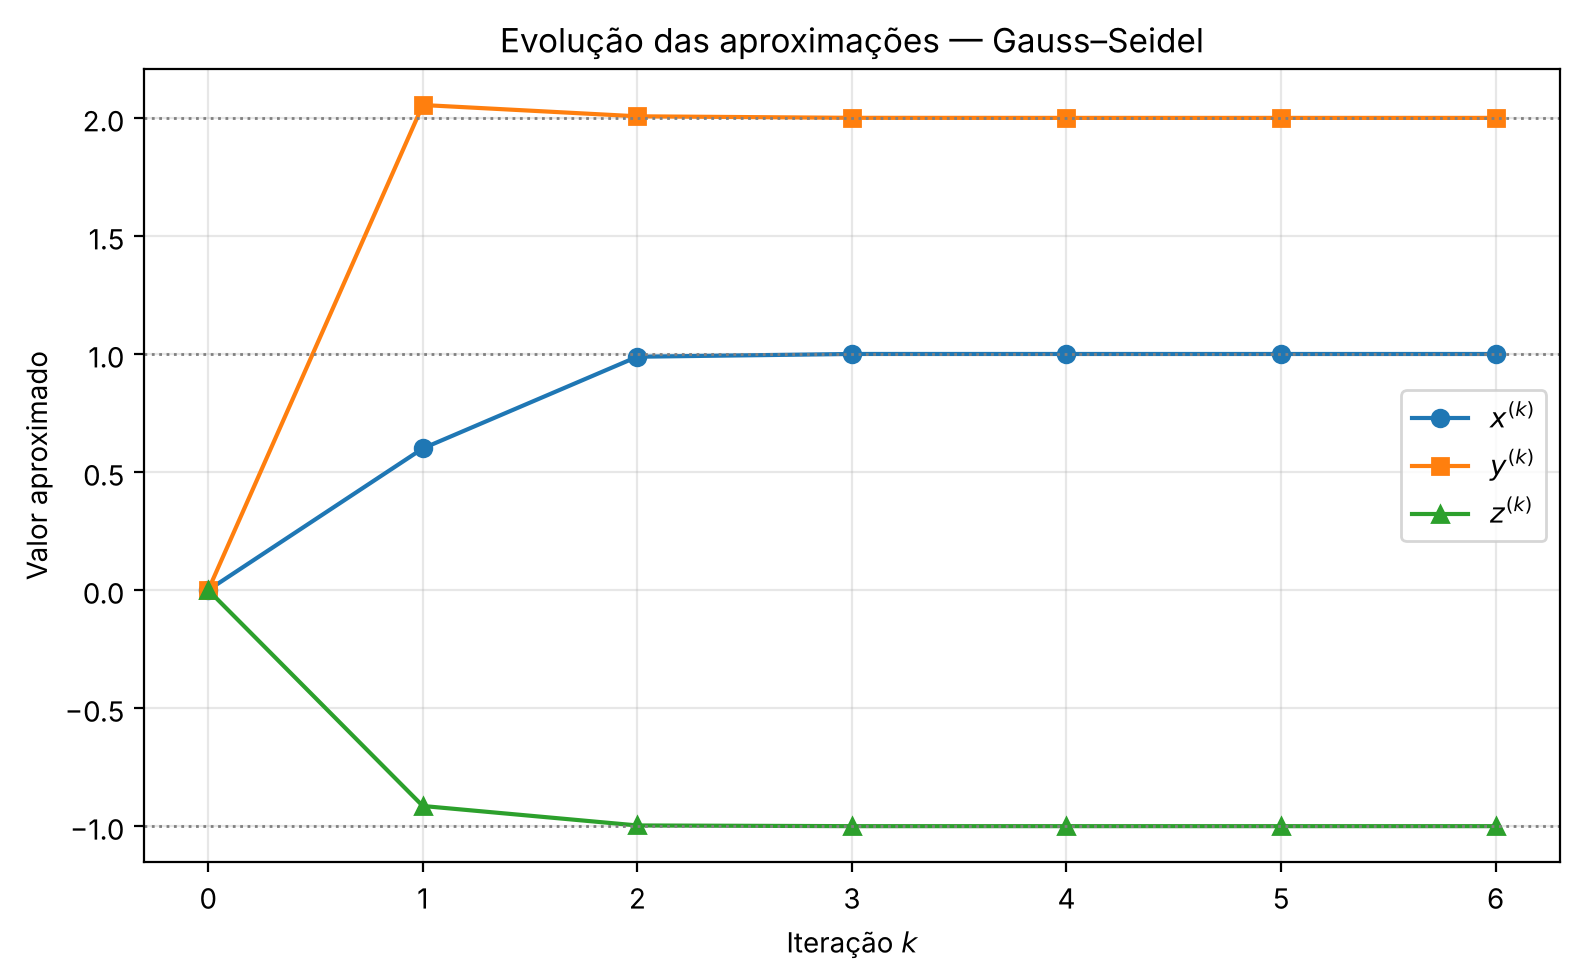

In [4]:
k = tabela["k"]

plt.figure(figsize=(8, 5))
plt.plot(k, tabela["x(k)"], "o-", label="$x^{(k)}$")
plt.plot(k, tabela["y(k)"], "s-", label="$y^{(k)}$")
plt.plot(k, tabela["z(k)"], "^-", label="$z^{(k)}$")

# linhas de referência na solução exata (1, 2, -1)
for valor in (1, 2, -1):
    plt.axhline(valor, color="gray", linestyle=":", linewidth=1)

plt.xlabel("Iteração $k$")
plt.ylabel("Valor aproximado")
plt.title("Evolução das aproximações — Gauss–Seidel")
plt.xticks(k)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("grafico_aproximacoes.png", dpi=200)
plt.show()

### b) Erro entre iterações em escala logarítmica

Linha tracejada: tolerância $10^{-5}$.

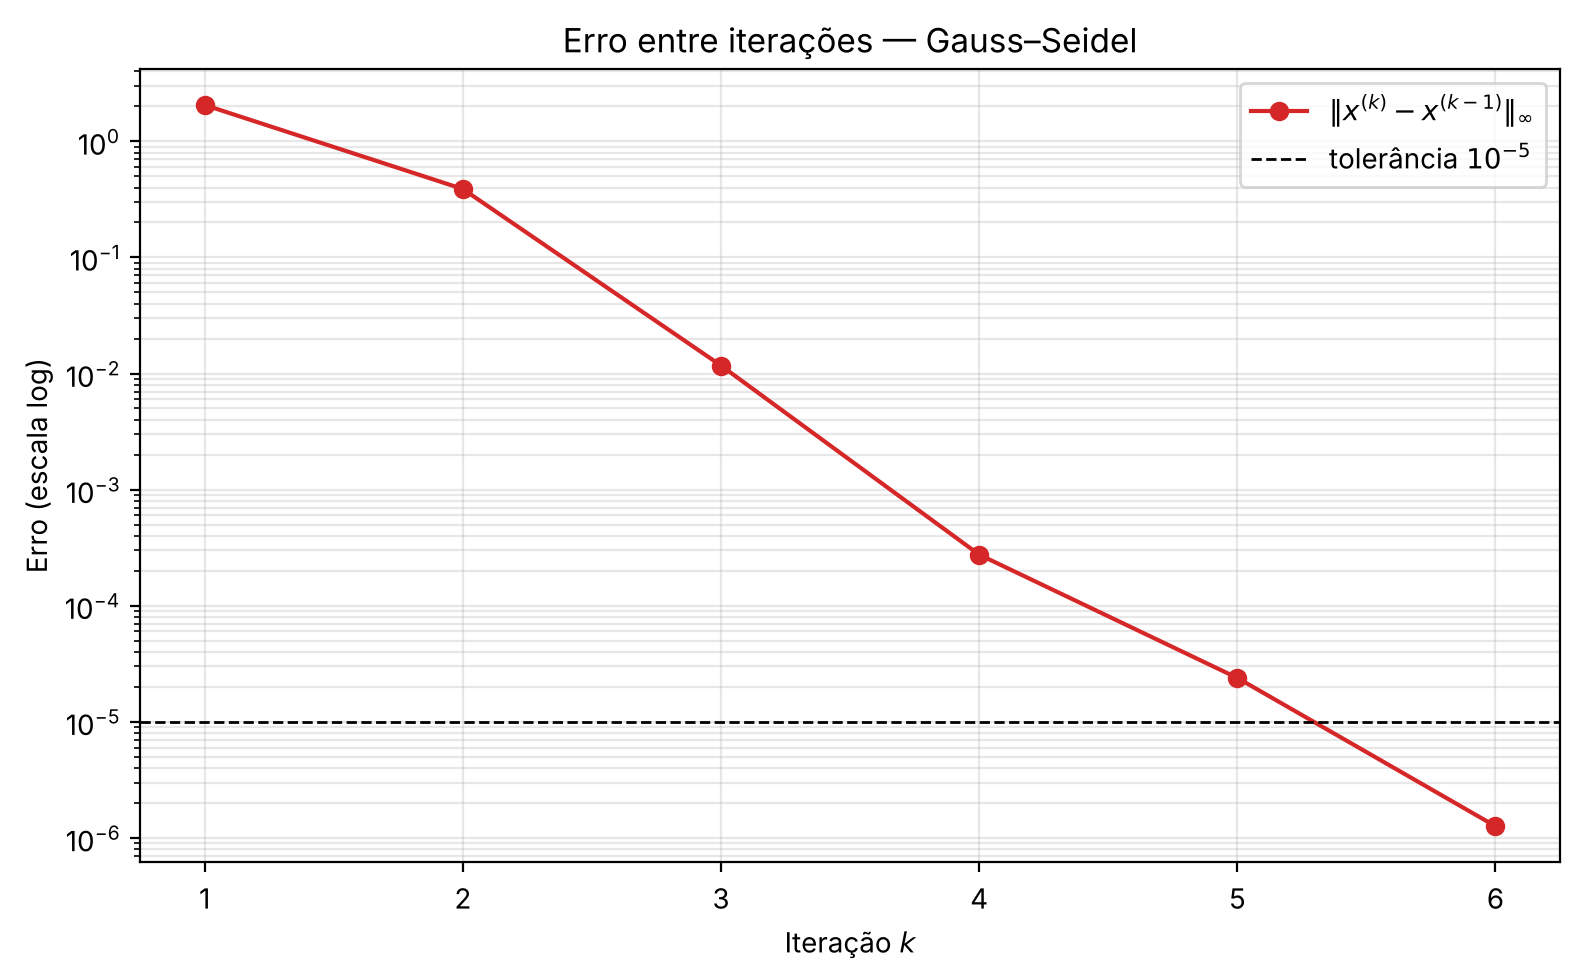

In [5]:
k_erro = tabela["k"][1:]
erros = tabela["||x(k) - x(k-1)||_inf"][1:]

plt.figure(figsize=(8, 5))
plt.semilogy(k_erro, erros, "o-", color="tab:red", label=r"$\|x^{(k)}-x^{(k-1)}\|_\infty$")
plt.axhline(1e-5, color="black", linestyle="--", linewidth=1, label="tolerância $10^{-5}$")
plt.xlabel("Iteração $k$")
plt.ylabel("Erro (escala log)")
plt.title("Erro entre iterações — Gauss–Seidel")
plt.xticks(k_erro)
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("grafico_erro.png", dpi=200)
plt.show()